# COVID-19 Patient Outcome Prediction — XGBoost Extension

**Objective:** Evaluate XGBoost as an additional model for predicting ICU admission, mechanical ventilation (MV), and death using four predefined feature groups.

**Workflow:** fixed train/validation/test split → validation-based hyperparameter selection → final test evaluation → baseline comparison → paired bootstrap analysis.

**Data:** 286 patients (140 train, 60 validation, 86 test). This is a small research dataset; results are for academic evaluation only and are not suitable for clinical decision-making.

**Before running:** Ensure the project files are available in `/content/sample_data/`: `features.csv`, `split.csv`, `test_results.csv`, `test_predictions.csv`, `xgboost_test_predictions.csv`, and `boot_idx.npy`. The last three are needed for the final paired bootstrap comparison. If your files are in another directory, update `DATA_DIR` below.

In [1]:
!pip -q install xgboost

In [4]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score,
    roc_curve, precision_recall_curve
)

warnings.filterwarnings("ignore")
SEED = 42
DATA_DIR = "/content/sample_data"

features_path = os.path.join(DATA_DIR, "features.csv")
split_path = os.path.join(DATA_DIR, "split.csv")
baseline_results_path = os.path.join(DATA_DIR, "test_results.csv")

for path in [features_path, split_path, baseline_results_path]:
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Required file not found: {path}. Upload the project files or update DATA_DIR."
        )

df_features = pd.read_csv(features_path)
splits = pd.read_csv(split_path)
baseline = pd.read_csv(baseline_results_path)

assert df_features["patient_id"].is_unique, "Duplicate patient IDs in features.csv."
assert splits["patient_id"].is_unique, "Duplicate patient IDs in split.csv."
assert set(df_features["patient_id"]) == set(splits["patient_id"]), (
    "features.csv and split.csv do not contain the same patients."
)

print(f"Patients: {len(df_features)}")
print("Fixed split sizes:", splits["split"].value_counts().to_dict())
print("Outcome positives:", df_features[["icu", "mv", "death"]].sum().to_dict())

Patients: 286
Fixed split sizes: {'train': 140, 'test': 86, 'val': 60}
Outcome positives: {'icu': 84, 'mv': 73, 'death': 51}


## Feature groups and fixed data partitions

The four predefined feature groups are:
- **Radiom:** radiomics features
- **RadioClin:** radiomics + clinical features
- **RadioClinLab:** radiomics + clinical + laboratory features
- **ClinLab:** clinical + laboratory features

Patient IDs, split labels, and outcome labels are excluded from model inputs.

In [5]:
df = df_features.merge(
    splits, on="patient_id", how="inner", validate="one_to_one"
)
train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()
test = df[df["split"] == "test"].copy()

def columns_with_prefixes(*prefixes):
    return [c for c in df.columns if c.startswith(prefixes)]

FEATURE_SETS = {
    "Radiom": columns_with_prefixes("rad_"),
    "RadioClin": columns_with_prefixes("rad_", "clin_"),
    "RadioClinLab": columns_with_prefixes("rad_", "clin_", "lab_"),
    "ClinLab": columns_with_prefixes("clin_", "lab_"),
}
TASKS = ["icu", "mv", "death"]

assert all(FEATURE_SETS.values()), "One or more feature groups are empty."
print(f"Train={len(train)}, validation={len(val)}, test={len(test)}")
display(pd.DataFrame({
    "feature_set": list(FEATURE_SETS),
    "n_features": [len(cols) for cols in FEATURE_SETS.values()]
}))
display(df.groupby("split")[TASKS].sum().rename_axis("split"))

Train=140, validation=60, test=86


,feature_set,n_features
0,Radiom,107
1,RadioClin,137
2,RadioClinLab,158
3,ClinLab,51


,icu,mv,death
split,,,
test,25,21,15
train,39,35,25
val,20,17,11


## Model selection

For each outcome and feature group, four XGBoost configurations are evaluated on the validation set. Median imputation is fitted on the training partition only during this selection stage. The configuration with the highest validation AUROC is selected; the test set is not used for tuning.

In [6]:
PARAM_GRID = [
    {"n_estimators": 100, "max_depth": 2, "learning_rate": 0.03, "min_child_weight": 3},
    {"n_estimators": 150, "max_depth": 2, "learning_rate": 0.05, "min_child_weight": 3},
    {"n_estimators": 100, "max_depth": 3, "learning_rate": 0.03, "min_child_weight": 5},
    {"n_estimators": 150, "max_depth": 3, "learning_rate": 0.05, "min_child_weight": 5},
]

def make_xgb(params):
    return XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=1,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=2.0,
        **params
    )

selected = {}
validation_rows = []

for task in TASKS:
    for data_name, feat_cols in FEATURE_SETS.items():
        # Imputation is fit on training data only.
        imputer = SimpleImputer(strategy="median")
        X_train = imputer.fit_transform(train[feat_cols])
        X_val = imputer.transform(val[feat_cols])
        y_train = train[task].astype(int).to_numpy()
        y_val = val[task].astype(int).to_numpy()

        best = None
        for params in PARAM_GRID:
            model = make_xgb(params)
            model.fit(X_train, y_train)
            prob = model.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, prob)
            ap = average_precision_score(y_val, prob)
            row = {
                "task": task, "data": data_name,
                "validation_AUROC": auc, "validation_AUPRC": ap,
                "params": str(params)
            }
            validation_rows.append(row)
            if best is None or auc > best["validation_AUROC"]:
                best = {
                    "task": task, "data": data_name, "features": feat_cols,
                    "params": params, "imputer": imputer, "model": model,
                    "validation_AUROC": auc, "validation_AUPRC": ap
                }
        selected[(task, data_name)] = best
        print(f"{task:5s} | {data_name:12s} | validation AUROC={best['validation_AUROC']:.3f} | {best['params']}")

validation_results = pd.DataFrame(validation_rows)
validation_results.to_csv(os.path.join(DATA_DIR, "xgboost_validation_grid.csv"), index=False)
best_validation = pd.DataFrame([
    {"task": t, "data": d, "validation_AUROC": selected[(t,d)]["validation_AUROC"],
     "validation_AUPRC": selected[(t,d)]["validation_AUPRC"],
     "params": str(selected[(t,d)]["params"])}
    for t in TASKS for d in FEATURE_SETS
])
display(best_validation)

icu   | Radiom       | validation AUROC=0.596 | {'n_estimators': 150, 'max_depth': 2, 'learning_rate': 0.05, 'min_child_weight': 3}
icu   | RadioClin    | validation AUROC=0.639 | {'n_estimators': 150, 'max_depth': 2, 'learning_rate': 0.05, 'min_child_weight': 3}
icu   | RadioClinLab | validation AUROC=0.635 | {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.03, 'min_child_weight': 3}
icu   | ClinLab      | validation AUROC=0.635 | {'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 5}
mv    | Radiom       | validation AUROC=0.631 | {'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 5}
mv    | RadioClin    | validation AUROC=0.752 | {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.03, 'min_child_weight': 3}
mv    | RadioClinLab | validation AUROC=0.731 | {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.03, 'min_child_weight': 3}
mv    | ClinLab      | validation AUROC=0.714 | {'n_estimators': 100, 'max_d

,task,data,validation_AUROC,validation_AUPRC,params
0,icu,Radiom,0.596250,0.461389,"{'n_estimators': 150, 'max_depth': 2, 'learnin..."
1,icu,RadioClin,0.638750,0.459148,"{'n_estimators': 150, 'max_depth': 2, 'learnin..."
2,icu,RadioClinLab,0.635000,0.436391,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
3,icu,ClinLab,0.635000,0.519708,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
4,mv,Radiom,0.630643,0.480265,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
5,mv,RadioClin,0.752394,0.531160,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
6,mv,RadioClinLab,0.730506,0.467359,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
7,mv,ClinLab,0.714090,0.487329,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
8,death,Radiom,0.769944,0.464447,"{'n_estimators': 150, 'max_depth': 3, 'learnin..."
9,death,RadioClin,0.751391,0.460330,"{'n_estimators': 150, 'max_depth': 2, 'learnin..."


## Final test evaluation

The selected configuration for each outcome/feature group is retrained on the combined training and validation partitions. The held-out test set is then evaluated once. Reported metrics include AUROC, AUPRC, accuracy, precision, recall, and F1 at a probability threshold of 0.5.

In [7]:
development = df[df["split"].isin(["train", "val"])].copy()
final_rows = []
test_predictions = {"patient_id": test["patient_id"].to_numpy()}
final_models = {}

for task in TASKS:
    y_test = test[task].astype(int).to_numpy()
    for data_name, feat_cols in FEATURE_SETS.items():
        cfg = selected[(task, data_name)]
        imputer = SimpleImputer(strategy="median")
        X_dev = imputer.fit_transform(development[feat_cols])
        X_test = imputer.transform(test[feat_cols])
        y_dev = development[task].astype(int).to_numpy()

        model = make_xgb(cfg["params"])
        model.fit(X_dev, y_dev)
        prob = model.predict_proba(X_test)[:, 1]
        pred = (prob >= 0.5).astype(int)

        final_models[(task, data_name)] = (imputer, model, feat_cols)
        test_predictions[f"{task}_{data_name}_xgb"] = prob
        final_rows.append({
            "task": task, "data": data_name, "model": "XGBoost",
            "AUROC": roc_auc_score(y_test, prob),
            "AUPRC": average_precision_score(y_test, prob),
            "ACC": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "validation_AUROC": cfg["validation_AUROC"],
            "params": str(cfg["params"])
        })

xgb_results = pd.DataFrame(final_rows)
xgb_results.to_csv(os.path.join(DATA_DIR, "xgboost_test_results.csv"), index=False)
pd.DataFrame(test_predictions).to_csv(os.path.join(DATA_DIR, "xgboost_test_predictions.csv"), index=False)
display(xgb_results.round(3))

,task,data,model,AUROC,AUPRC,ACC,precision,recall,F1,validation_AUROC,params
0,icu,Radiom,XGBoost,0.548,0.343,0.663,0.357,0.200,0.256,0.596,"{'n_estimators': 150, 'max_depth': 2, 'learnin..."
1,icu,RadioClin,XGBoost,0.582,0.370,0.709,0.500,0.280,0.359,0.639,"{'n_estimators': 150, 'max_depth': 2, 'learnin..."
2,icu,RadioClinLab,XGBoost,0.668,0.524,0.767,0.727,0.320,0.444,0.635,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
3,icu,ClinLab,XGBoost,0.741,0.605,0.767,0.667,0.400,0.500,0.635,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
4,mv,Radiom,XGBoost,0.641,0.392,0.709,0.250,0.095,0.138,0.631,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
5,mv,RadioClin,XGBoost,0.655,0.399,0.733,0.375,0.143,0.207,0.752,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
6,mv,RadioClinLab,XGBoost,0.653,0.418,0.756,0.500,0.238,0.323,0.731,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
7,mv,ClinLab,XGBoost,0.681,0.447,0.767,0.538,0.333,0.412,0.714,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
8,death,Radiom,XGBoost,0.598,0.310,0.826,0.500,0.067,0.118,0.770,"{'n_estimators': 150, 'max_depth': 3, 'learnin..."
9,death,RadioClin,XGBoost,0.714,0.497,0.849,0.750,0.200,0.316,0.751,"{'n_estimators': 150, 'max_depth': 2, 'learnin..."


## Baseline comparison

Compare XGBoost with the existing reference-pipeline results for the same outcome and feature group. Positive differences favour XGBoost; negative differences favour the baseline. This is a comparison with the saved baseline results, not a claim of exact reproduction of the original paper.

In [8]:
base = baseline.copy()
base["model"] = base["model"].astype(str)
base = base.rename(columns={
    "AUROC": "baseline_AUROC",
    "AUPRC": "baseline_AUPRC",
    "ACC": "baseline_ACC",
    "model": "baseline_model"
})
comparison = base.merge(
    xgb_results[["task", "data", "AUROC", "AUPRC", "ACC", "precision", "recall", "F1"]],
    on=["task", "data"], how="inner", validate="one_to_one"
).rename(columns={
    "AUROC": "xgb_AUROC", "AUPRC": "xgb_AUPRC", "ACC": "xgb_ACC"
})
comparison["delta_AUROC"] = comparison["xgb_AUROC"] - comparison["baseline_AUROC"]
comparison["delta_AUPRC"] = comparison["xgb_AUPRC"] - comparison["baseline_AUPRC"]
comparison["delta_ACC"] = comparison["xgb_ACC"] - comparison["baseline_ACC"]
comparison.to_csv(os.path.join(DATA_DIR, "baseline_vs_xgboost.csv"), index=False)
display(comparison[[
    "task", "data", "baseline_model", "baseline_AUROC", "xgb_AUROC", "delta_AUROC",
    "baseline_AUPRC", "xgb_AUPRC", "delta_AUPRC", "baseline_ACC", "xgb_ACC", "delta_ACC"
]].round(3))

,task,data,baseline_model,baseline_AUROC,xgb_AUROC,delta_AUROC,baseline_AUPRC,xgb_AUPRC,delta_AUPRC,baseline_ACC,xgb_ACC,delta_ACC
0,icu,Radiom,SMOTEENN+LASSO + LightGBM,0.631,0.548,-0.083,0.424,0.343,-0.081,0.523,0.663,0.140
1,icu,RadioClin,Raw + RF,0.645,0.582,-0.063,0.442,0.370,-0.072,0.698,0.709,0.012
2,icu,RadioClinLab,SMOTEENN + LR,0.676,0.668,-0.008,0.579,0.524,-0.055,0.407,0.767,0.360
3,icu,ClinLab,Raw + RF,0.842,0.741,-0.101,0.706,0.605,-0.101,0.721,0.767,0.047
4,mv,Radiom,Raw + LR,0.730,0.641,-0.089,0.660,0.392,-0.268,0.837,0.709,-0.128
5,mv,RadioClin,Raw + MLP,0.649,0.655,0.006,0.459,0.399,-0.059,0.744,0.733,-0.012
6,mv,RadioClinLab,Raw + SVM,0.760,0.653,-0.108,0.661,0.418,-0.243,0.860,0.756,-0.105
7,mv,ClinLab,Raw + LightGBM,0.688,0.681,-0.007,0.448,0.447,-0.001,0.698,0.767,0.070
8,death,Radiom,Raw + LightGBM,0.623,0.598,-0.024,0.353,0.310,-0.042,0.802,0.826,0.023
9,death,RadioClin,SMOTEENN+PCA + LR,0.766,0.714,-0.053,0.387,0.497,0.109,0.616,0.849,0.233


## Performance plots

The first three plots compare baseline and XGBoost AUROC. The lower row shows XGBoost ROC and precision–recall curves on the held-out test set.

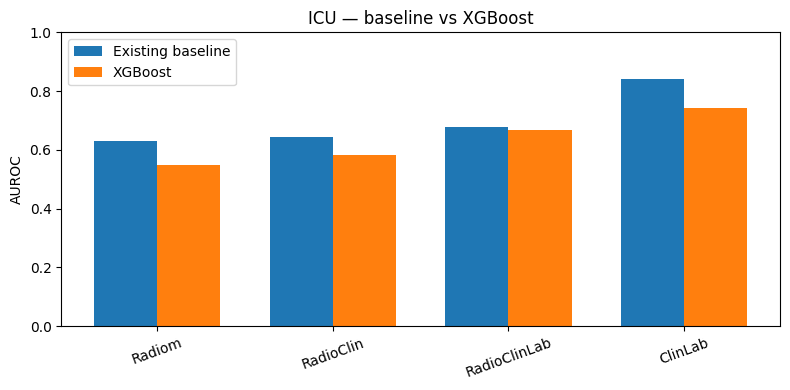

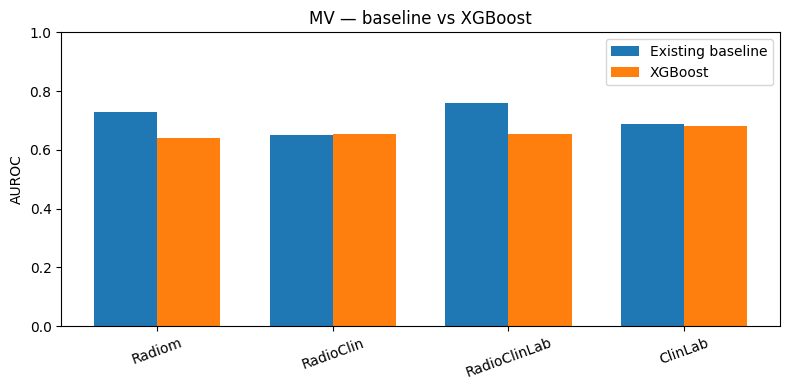

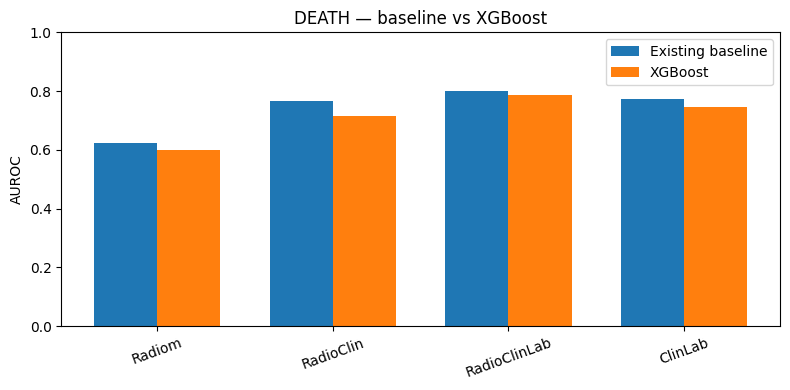

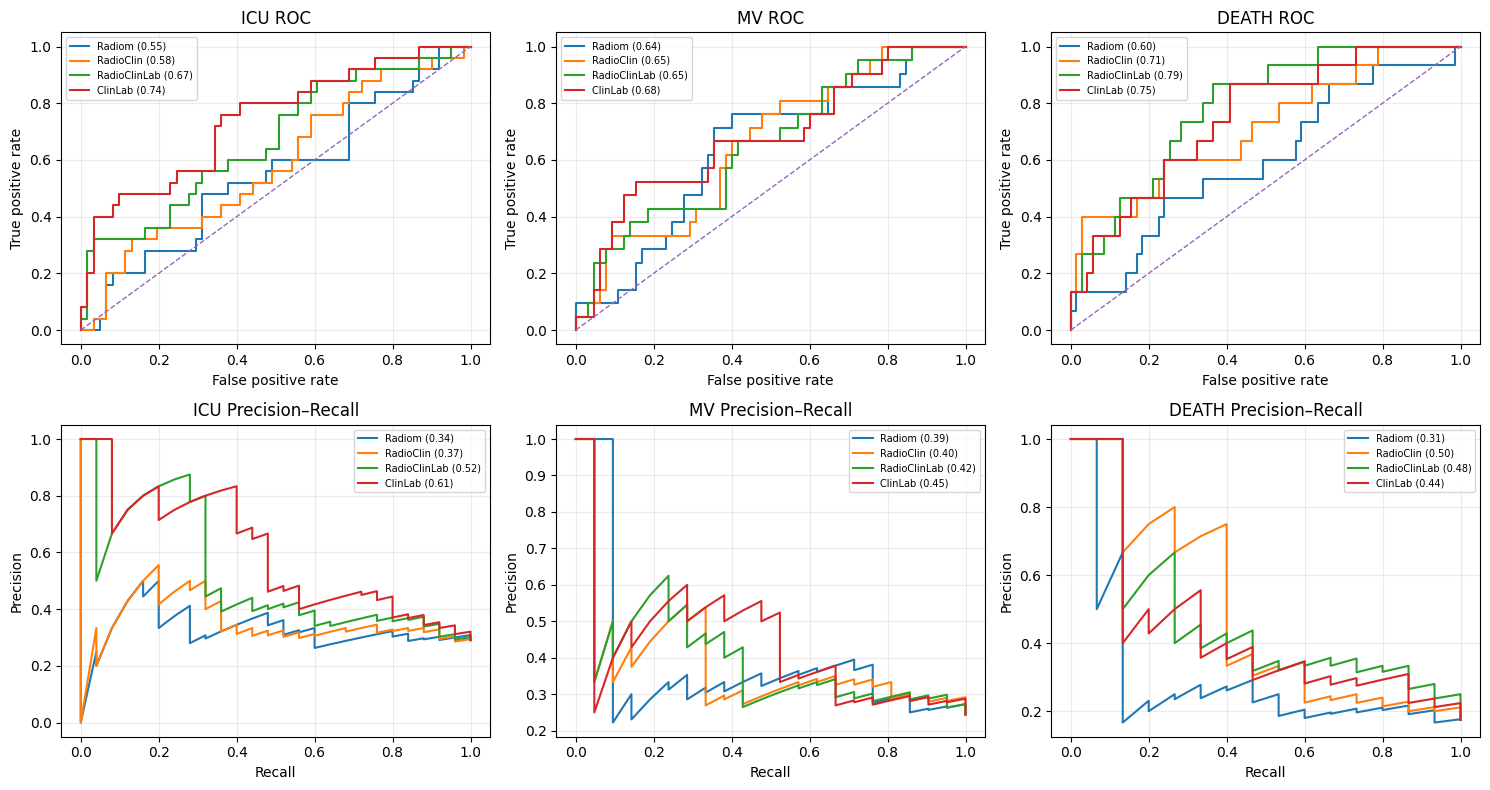

In [9]:
# AUROC comparison by task and feature group
for task in TASKS:
    sub = comparison[comparison["task"] == task].copy()
    x = np.arange(len(sub))
    width = 0.36
    plt.figure(figsize=(8, 4))
    plt.bar(x - width/2, sub["baseline_AUROC"], width, label="Existing baseline")
    plt.bar(x + width/2, sub["xgb_AUROC"], width, label="XGBoost")
    plt.xticks(x, sub["data"], rotation=20)
    plt.ylim(0, 1)
    plt.ylabel("AUROC")
    plt.title(f"{task.upper()} — baseline vs XGBoost")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ROC and PR curves for XGBoost models on the held-out test set
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, task in enumerate(TASKS):
    y = test[task].astype(int).to_numpy()
    for data_name in FEATURE_SETS:
        prob = test_predictions[f"{task}_{data_name}_xgb"]
        fpr, tpr, _ = roc_curve(y, prob)
        axes[0, j].plot(fpr, tpr, label=f"{data_name} ({roc_auc_score(y, prob):.2f})")
        precision, recall, _ = precision_recall_curve(y, prob)
        axes[1, j].plot(recall, precision, label=f"{data_name} ({average_precision_score(y, prob):.2f})")
    axes[0, j].plot([0, 1], [0, 1], "--", linewidth=1)
    axes[0, j].set_title(f"{task.upper()} ROC")
    axes[0, j].set_xlabel("False positive rate")
    axes[0, j].set_ylabel("True positive rate")
    axes[1, j].set_title(f"{task.upper()} Precision–Recall")
    axes[1, j].set_xlabel("Recall")
    axes[1, j].set_ylabel("Precision")
    axes[0, j].legend(fontsize=7)
    axes[1, j].legend(fontsize=7)
    axes[0, j].grid(alpha=0.25)
    axes[1, j].grid(alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "xgboost_curves.png"), dpi=160)
plt.show()

## Summary of test results

Use these results descriptively. The best-performing feature group is selected here for summarization only; it is not a new model-selection step. Avoid claiming overall superiority based on one metric.

In [10]:
for task in TASKS:
    sub = comparison[comparison["task"] == task]
    best_auc = sub.loc[sub["xgb_AUROC"].idxmax()]
    best_delta = sub.loc[sub["delta_AUROC"].idxmax()]
    print(f"\n{task.upper()}")
    print(f"Best XGBoost feature set by test AUROC: {best_auc['data']} "
          f"(XGBoost AUROC={best_auc['xgb_AUROC']:.3f}, "
          f"baseline AUROC={best_auc['baseline_AUROC']:.3f})")
    print(f"Largest AUROC change vs baseline: {best_delta['data']} "
          f"(delta={best_delta['delta_AUROC']:+.3f})")

print("\nFiles saved in /content:")
for name in [
    "xgboost_validation_grid.csv",
    "xgboost_test_results.csv",
    "xgboost_test_predictions.csv",
    "baseline_vs_xgboost.csv",
    "xgboost_curves.png"
]:
    print("-", name)


ICU
Best XGBoost feature set by test AUROC: ClinLab (XGBoost AUROC=0.741, baseline AUROC=0.842)
Largest AUROC change vs baseline: RadioClinLab (delta=-0.008)

MV
Best XGBoost feature set by test AUROC: ClinLab (XGBoost AUROC=0.681, baseline AUROC=0.688)
Largest AUROC change vs baseline: RadioClin (delta=+0.006)

DEATH
Best XGBoost feature set by test AUROC: RadioClinLab (XGBoost AUROC=0.786, baseline AUROC=0.800)
Largest AUROC change vs baseline: RadioClinLab (delta=-0.014)

Files saved in /content:
- xgboost_validation_grid.csv
- xgboost_test_results.csv
- xgboost_test_predictions.csv
- baseline_vs_xgboost.csv
- xgboost_curves.png


## Paired bootstrap comparison

This final check uses the supplied bootstrap indices to compare both models on the same resampled test patients. It verifies patient ordering before calculating paired AUROC and AUPRC differences. The 95% percentile intervals are descriptive and approximate because only 30 resamples are available.

Outputs: `bootstrap_paired_results.csv` and `bootstrap_comparison_summary.csv`.

In [11]:
# Paired bootstrap comparison using the shared 30 resamples.
boot_path = os.path.join(DATA_DIR, "boot_idx.npy")
baseline_pred_path = os.path.join(DATA_DIR, "test_predictions.csv")
xgb_pred_path = os.path.join(DATA_DIR, "xgboost_test_predictions.csv")

for path in [boot_path, baseline_pred_path, xgb_pred_path]:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Required bootstrap-comparison file not found: {path}")

boot = np.load(boot_path)
baseline_pred = pd.read_csv(baseline_pred_path)
xgb_pred = pd.read_csv(xgb_pred_path)

# Recreate the test table in the same order used by the fixed split and predictions.
test_ids = test["patient_id"].tolist()
baseline_ids = baseline_pred["patient_id"].tolist()
xgb_ids = xgb_pred["patient_id"].tolist()

assert len(test_ids) == 86 and len(set(test_ids)) == 86, "Unexpected test patient list."
assert test_ids == baseline_ids, "Baseline predictions are not in the fixed test-table order."
assert test_ids == xgb_ids, "XGBoost predictions are not in the fixed test-table order."
assert boot.shape == (30, len(test_ids)), f"Unexpected bootstrap shape: {boot.shape}"
assert boot.min() >= 0 and boot.max() < len(test_ids), "Bootstrap index out of range."

y_test = test.set_index("patient_id").loc[test_ids, TASKS].astype(int)

bootstrap_rows = []
for task in TASKS:
    y = y_test[task].to_numpy()
    for feature_set in FEATURE_SETS:
        base_prob = baseline_pred[f"{task}_{feature_set}"].to_numpy()
        xgb_prob = xgb_pred[f"{task}_{feature_set}_xgb"].to_numpy()

        for b, idx in enumerate(boot):
            y_b = y[idx]
            if len(np.unique(y_b)) < 2:
                continue

            base_auc = roc_auc_score(y_b, base_prob[idx])
            xgb_auc = roc_auc_score(y_b, xgb_prob[idx])
            base_ap = average_precision_score(y_b, base_prob[idx])
            xgb_ap = average_precision_score(y_b, xgb_prob[idx])

            bootstrap_rows.append({
                "bootstrap": b + 1,
                "task": task,
                "feature_set": feature_set,
                "baseline_AUROC": base_auc,
                "xgb_AUROC": xgb_auc,
                "delta_AUROC": xgb_auc - base_auc,
                "baseline_AUPRC": base_ap,
                "xgb_AUPRC": xgb_ap,
                "delta_AUPRC": xgb_ap - base_ap
            })

bootstrap_results = pd.DataFrame(bootstrap_rows)
summary_rows = []
for (task, feature_set), group in bootstrap_results.groupby(["task", "feature_set"]):
    row = {
        "task": task,
        "feature_set": feature_set,
        "valid_resamples": len(group)
    }
    for metric in ["AUROC", "AUPRC"]:
        delta = group[f"delta_{metric}"]
        row[f"mean_delta_{metric}"] = delta.mean()
        row[f"CI95_low_{metric}"] = delta.quantile(0.025)
        row[f"CI95_high_{metric}"] = delta.quantile(0.975)
        row[f"fraction_positive_{metric}"] = (delta > 0).mean()
    summary_rows.append(row)

bootstrap_summary = pd.DataFrame(summary_rows)
bootstrap_results.to_csv(os.path.join(DATA_DIR, "bootstrap_paired_results.csv"), index=False)
bootstrap_summary.to_csv(os.path.join(DATA_DIR, "bootstrap_comparison_summary.csv"), index=False)

print("Patient order verified:", test_ids == baseline_ids == xgb_ids)
print(f"Valid paired resample comparisons: {len(bootstrap_results)}")
print("Note: intervals are descriptive and approximate because only 30 resamples were supplied.")
display(bootstrap_summary.round(3))

Patient order verified: True
Valid paired resample comparisons: 360
Note: intervals are descriptive and approximate because only 30 resamples were supplied.


,task,feature_set,valid_resamples,mean_delta_AUROC,CI95_low_AUROC,CI95_high_AUROC,fraction_positive_AUROC,mean_delta_AUPRC,CI95_low_AUPRC,CI95_high_AUPRC,fraction_positive_AUPRC
0,death,ClinLab,30,-0.037,-0.075,0.009,0.100,0.023,-0.104,0.137,0.633
1,death,RadioClin,30,-0.039,-0.203,0.100,0.300,0.087,-0.103,0.282,0.733
2,death,RadioClinLab,30,-0.007,-0.110,0.128,0.467,-0.005,-0.225,0.171,0.500
3,death,Radiom,30,-0.016,-0.161,0.147,0.433,-0.030,-0.172,0.087,0.433
4,icu,ClinLab,30,-0.109,-0.173,-0.062,0.000,-0.107,-0.205,-0.012,0.033
5,icu,RadioClin,30,-0.066,-0.149,0.009,0.100,-0.061,-0.174,0.015,0.167
6,icu,RadioClinLab,30,0.013,-0.091,0.138,0.633,-0.026,-0.203,0.103,0.467
7,icu,Radiom,30,-0.062,-0.192,0.071,0.067,-0.067,-0.196,0.045,0.167
8,mv,ClinLab,30,-0.016,-0.101,0.048,0.333,-0.008,-0.118,0.115,0.433
9,mv,RadioClin,30,0.011,-0.079,0.119,0.433,-0.082,-0.283,0.036,0.133
